In [3]:
# !pip install gensim

from pathlib import Path
import html
import json
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay

from collections import Counter
import gensim.downloader as api
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Working directory:", ROOT)
print("Python dependencies imported successfully.")

Working directory: c:\Users\harih\OneDrive\Documents\School\COMP-5313 Artificial Intelligence\Projects\P2 WordEmbedding\YourName_Project2_Submission
Python dependencies imported successfully.


In [ ]:
import pandas as pd

splits = {'train': 'plain_text/train-00000-of-00001.parquet', 'test': 'plain_text/test-00000-of-00001.parquet', 'unsupervised': 'plain_text/unsupervised-00000-of-00001.parquet'}

train_df = pd.read_parquet("hf://datasets/stanfordnlp/imdb/" + splits["train"])
test_df  = pd.read_parquet("hf://datasets/stanfordnlp/imdb/" + splits["test"])

print("Training set \n" + train_df.head(5))
print("\nTesting set  \n" + test_df.head(5))

In [5]:
required = {"text", "label"}
assert required.issubset(train_df.columns) and required.issubset(test_df.columns)
assert set(train_df["label"].dropna().unique()) == {0, 1}
assert set(test_df["label"].dropna().unique()) == {0, 1}
assert len(train_df) == 25_000 and len(test_df) == 25_000, "Unexpected split sizes"
assert not train_df[["text", "label"]].isna().any().any()
assert not test_df[["text", "label"]].isna().any().any()

print("Train:", train_df.shape, "\nTest:", test_df.shape)
print("Train label counts:", train_df["label"].value_counts().sort_index().to_dict())
print("Test label counts:", test_df["label"].value_counts().sort_index().to_dict())

print("\nExample review excerpt:", train_df["text"].iloc[0][:220])

Train: (25000, 2) 
Test: (25000, 2)
Train label counts: {0: 12500, 1: 12500}
Test label counts: {0: 12500, 1: 12500}

Example review excerpt: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter th


In [6]:
# TEXT NORMALIZATION

def clean_text(text: str) -> str:
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

x_train = train_df["text"].map(clean_text).tolist()
x_test = test_df["text"].map(clean_text).tolist()

y_train = train_df["label"].to_numpy(dtype=int)
y_test = test_df["label"].to_numpy(dtype=int)

print("Before:", train_df["text"].iloc[0])
print("After: ", x_train[0])

Before: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far betw

In [7]:
# MODEL I: TF-IDF and Logistic Regression

t0 = time.perf_counter()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(x_train)
X_test_tfidf = vectorizer.transform(x_test)
model_tfidf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver="liblinear")
model_tfidf.fit(X_train_tfidf, y_train)
tfidf_fit_seconds = time.perf_counter() - t0
pred_tfidf = model_tfidf.predict(X_test_tfidf)

print("TF-IDF train matrix:", X_train_tfidf.shape)
print(f"TF-IDF fit time (vectorizer + classifier): {tfidf_fit_seconds:.2f}s")
print(f"TF-IDF test accuracy: {accuracy_score(y_test, pred_tfidf):.4%}")

print("\nCONFUSION MATRIX\n" + classification_report(y_test, pred_tfidf, target_names=["Negative", "Positive"], digits=4))

TF-IDF train matrix: (25000, 100000)
TF-IDF fit time (vectorizer + classifier): 25.86s
TF-IDF test accuracy: 89.9360%

CONFUSION MATRIX
              precision    recall  f1-score   support

    Negative     0.9029    0.8950    0.8989     12500
    Positive     0.8959    0.9038    0.8998     12500

    accuracy                         0.8994     25000
   macro avg     0.8994    0.8994    0.8994     25000
weighted avg     0.8994    0.8994    0.8994     25000



In [8]:
# MODEL II: Pre-trained GloVe and Logistic Regression model

print("Loading pretrained glove-wiki-gigaword-50 vectors (first run downloads ~66 MB)...")
try:
    glove = api.load("glove-wiki-gigaword-50")
except Exception as exc:
    raise RuntimeError("GloVe download/load failed. Check internet access and gensim/scipy installation; rerun this cell.") from exc

EMBED_DIM = glove.vector_size
print("Pretrained embedding dimension:", EMBED_DIM)

def glove_review_vector(text: str) -> np.ndarray:
    tokens = text.split()
    vectors = [glove[w] for w in tokens if w in glove]
    return np.mean(vectors, axis=0) if vectors else np.zeros(EMBED_DIM, dtype=np.float32)

t0 = time.perf_counter()

X_train_glove = np.vstack([glove_review_vector(text) for text in x_train]).astype(np.float32)
X_test_glove = np.vstack([glove_review_vector(text) for text in x_test]).astype(np.float32)

model_glove = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver="liblinear")
model_glove.fit(X_train_glove, y_train)

glove_fit_seconds = time.perf_counter() - t0
pred_glove = model_glove.predict(X_test_glove)

print("GloVe train matrix:", X_train_glove.shape)
print(f"GloVe feature construction + classifier fit time (pretrained download excluded): {glove_fit_seconds:.2f}s")
print(f"GloVe test accuracy: {accuracy_score(y_test, pred_glove):.4%}")

print("\nCONFUSION MATRIX\n" + classification_report(y_test, pred_glove, target_names=["Negative", "Positive"], digits=4))

Loading pretrained glove-wiki-gigaword-50 vectors (first run downloads ~66 MB)...
Pretrained embedding dimension: 50
GloVe train matrix: (25000, 50)
GloVe feature construction + classifier fit time (pretrained download excluded): 17.55s
GloVe test accuracy: 75.6440%

CONFUSION MATRIX
              precision    recall  f1-score   support

    Negative     0.7504    0.7685    0.7593     12500
    Positive     0.7628    0.7444    0.7535     12500

    accuracy                         0.7564     25000
   macro avg     0.7566    0.7564    0.7564     25000
weighted avg     0.7566    0.7564    0.7564     25000



                           Model  Accuracy  Precision (weighted)  Recall (weighted)  F1 (weighted)  Fit/feature time (s)
    TF-IDF + Logistic Regression    0.8994                0.8994             0.8994         0.8994               25.8642
GloVe mean + Logistic Regression    0.7564                0.7566             0.7564         0.7564               17.5455


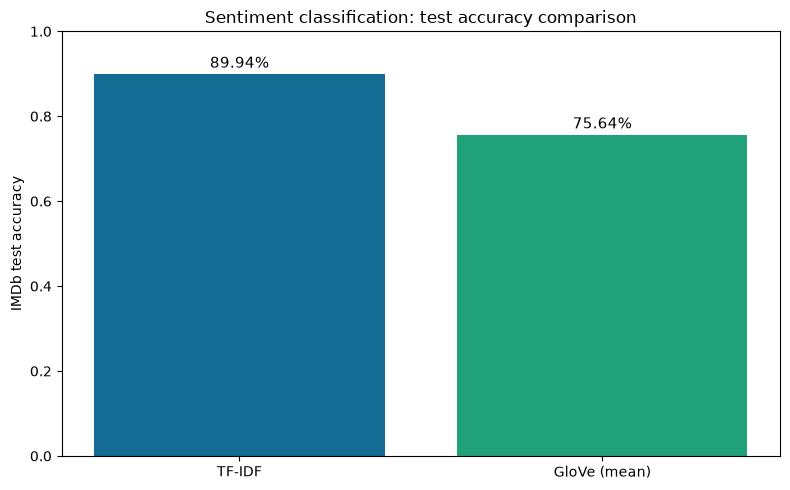

In [9]:
# Model comparison

def evaluate(name, predicted, seconds):
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, predicted, average="weighted", zero_division=0)
    return {"Model": name, "Accuracy": float(accuracy_score(y_test, predicted)),
            "Precision (weighted)": float(precision), "Recall (weighted)": float(recall),
            "F1 (weighted)": float(f1), "Fit/feature time (s)": float(seconds)}

results = pd.DataFrame([
    evaluate("TF-IDF + Logistic Regression", pred_tfidf, tfidf_fit_seconds),
    evaluate("GloVe mean + Logistic Regression", pred_glove, glove_fit_seconds),
])
print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
results.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(results.to_dict(orient="records"), f, indent=2)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["TF-IDF", "GloVe (mean)"], results["Accuracy"], color=["#146c94", "#21a179"])
ax.set_ylim(0, 1)
ax.set_ylabel("IMDb test accuracy")
ax.set_title("Sentiment classification: test accuracy comparison")
for b, v in zip(bars, results["Accuracy"]):
    ax.text(b.get_x() + b.get_width()/2, v + .015, f"{v:.2%}", ha="center", fontsize=11)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "accuracy_comparison.png", dpi=180)
plt.show()

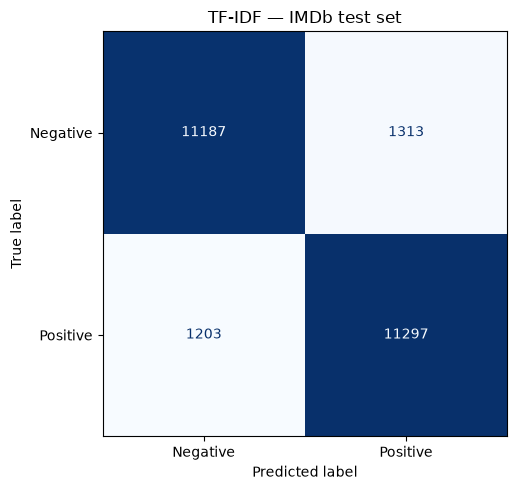

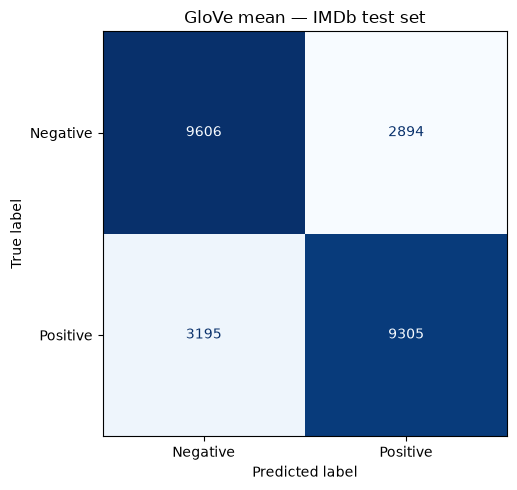

In [10]:
# Comparison 2: Confusion matrices

for label, pred, outfile in [
    ("TF-IDF", pred_tfidf, "confusion_matrix_tfidf.png"),
    ("GloVe mean", pred_glove, "confusion_matrix_glove.png")
]:
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Negative", "Positive"], ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{label} — IMDb test set")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / outfile, dpi=180)
    plt.show()

In [16]:
# Prediction of user-input values

# while True:
#     userReview = input("Enter a review (or -1 to exit): ").strip()

#     if userReview == "-1":
#         break
#     if not userReview:
#         continue

#     cleaned = clean_text(userReview)

#     tfidf_pred = model_tfidf.predict(vectorizer.transform([cleaned]))[0]
#     glove_pred = model_glove.predict(glove_review_vector(cleaned).reshape(1, -1))[0]

#     print("  TF-IDF:", "Positive" if tfidf_pred else "Negative")
#     print("  GloVe: ", "Positive" if glove_pred else "Negative")

print("=" * 60)
print(" INTERACTIVE SENTIMENT PREDICTION INTERFACE ")
print("=" * 60)

while True:
    try:
        userReview = input("\nEnter a review (or -1 to exit): ").strip()
    except (KeyboardInterrupt, EOFError):
        break

    if userReview == "-1":
        print("\nExiting predictor.")
        break
    if not userReview:
        continue

    cleaned = clean_text(userReview)

    tfidf_pred = model_tfidf.predict(vectorizer.transform([cleaned]))[0]
    glove_pred = model_glove.predict(glove_review_vector(cleaned).reshape(1, -1))[0]

    print(f"\n  [Input]:  \"{userReview}\"")
    print(f"  TF-IDF:   ", "Positive" if tfidf_pred else "Negative")
    print(f"  GloVe:    ", "Positive" if glove_pred else "Negative")
    print("-" * 60)

 INTERACTIVE SENTIMENT PREDICTION INTERFACE 

  [Input]:  "this movie LITERALLY changed my life. I will never live the same way again"
  TF-IDF:    Positive
  GloVe:     Positive
------------------------------------------------------------

  [Input]:  "this movie LITERALLY changed my life but in a bad way"
  TF-IDF:    Negative
  GloVe:     Negative
------------------------------------------------------------

  [Input]:  "this was the citizen kane of movies"
  TF-IDF:    Negative
  GloVe:     Positive
------------------------------------------------------------

Exiting predictor.
